<a href="https://colab.research.google.com/github/Shida78/movielens-data-analysis/blob/main/movielens_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Анализ данных: MovieLens и California Housing

Автор: Антон Кулиш

Учебный проект по обработке и визуализации данных на Python (pandas, matplotlib, seaborn).

**Что сделано**
- MovieLens 1M: объединение трёх таблиц, средние оценки по полу, фильмы с наибольшей разницей мнений, средний рейтинг жанров по возрастным группам;
- California Housing: корреляции признаков с ценой жилья.

**Данные.** Файлы MovieLens 1M (`movies.dat`, `ratings.dat`, `users.dat`) нужно скачать отдельно: https://grouplens.org/datasets/movielens/1m/ и указать папку с ними в переменной `DATA_DIR` ниже. California Housing подгружается из scikit-learn автоматически.

## 1. Подготовка

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Папка с файлами MovieLens 1M (movies.dat, ratings.dat, users.dat).
# В Google Colab: смонтируйте Диск (from google.colab import drive; drive.mount("/content/drive"))
# и укажите путь, например "/content/drive/MyDrive/Colab Notebooks".
DATA_DIR = "ml-1m"

## 2. MovieLens 1M: загрузка и объединение таблиц

В трёх файлах хранятся фильмы, оценки и пользователи. Объединяем их по `MovieId` и `UserId`, чтобы у каждой оценки были и название фильма, и данные пользователя.

In [13]:
!wget -q https://files.grouplens.org/datasets/movielens/ml-1m.zip
!unzip -q -o ml-1m.zip

In [14]:
def read_dat(name, columns):
    """Читает файл MovieLens формата `значение::значение::...`."""
    return pd.read_csv(
        f"{DATA_DIR}/{name}",
        sep="::",
        engine="python",    # разделитель из двух символов работает только в python-движке
        header=None,
        names=columns,
        encoding="latin-1",  # в оригинальных файлах MovieLens такая кодировка
    )


movies = read_dat("movies.dat", ["MovieId", "Title", "Genres"])
ratings = read_dat("ratings.dat", ["UserId", "MovieId", "Rating", "Timestamp"])
users = read_dat("users.dat", ["UserId", "Gender", "Age", "Occupation", "Zip-code"])

data = ratings.merge(movies, on="MovieId").merge(users, on="UserId")
print(f"Оценок: {len(data):,}, фильмов: {len(movies):,}, пользователей: {len(users):,}")
data.head()

Оценок: 1,000,209, фильмов: 3,883, пользователей: 6,040


,UserId,MovieId,Rating,Timestamp,Title,Genres,Gender,Age,Occupation,Zip-code
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,F,1,10,48067
1,1,661,3,978302109,James and the Giant Peach (1996),Animation|Children's|Musical,F,1,10,48067
2,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,F,1,10,48067
3,1,3408,4,978300275,Erin Brockovich (2000),Drama,F,1,10,48067
4,1,2355,5,978824291,"Bug's Life, A (1998)",Animation|Children's|Comedy,F,1,10,48067


## 3. Самые высоко оценённые фильмы: мужчины и женщины

Берём только фильмы, у которых не меньше 250 оценок: среднее по малому числу голосов ненадёжно.

In [15]:
MIN_RATINGS = 250

counts = data["Title"].value_counts()
popular = data[data["Title"].isin(counts[counts >= MIN_RATINGS].index)]
print(f"Фильмов с {MIN_RATINGS}+ оценками: {popular['Title'].nunique()}")

mean_by_gender = popular.pivot_table(
    index="Title", columns="Gender", values="Rating", aggfunc="mean"
)

print("Топ-5 по оценкам женщин:")
display(mean_by_gender["F"].nlargest(5).round(2))
print("Топ-5 по оценкам мужчин:")
display(mean_by_gender["M"].nlargest(5).round(2))

Фильмов с 250+ оценками: 1216
Топ-5 по оценкам женщин:


,F
Title,
"Close Shave, A (1995)",4.64
"Wrong Trousers, The (1993)",4.59
Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),4.57
Wallace & Gromit: The Best of Aardman Animation (1996),4.56
Schindler's List (1993),4.56


Топ-5 по оценкам мужчин:


,M
Title,
"Godfather, The (1972)",4.58
Seven Samurai (The Magnificent Seven) (Shichinin no samurai) (1954),4.58
"Shawshank Redemption, The (1994)",4.56
Raiders of the Lost Ark (1981),4.52
"Usual Suspects, The (1995)",4.52


## 4. Где мнения мужчин и женщин расходятся сильнее всего

Для каждого фильма считаем разницу средних оценок. Синий цвет: мужчинам фильм нравится больше, красный: женщинам.

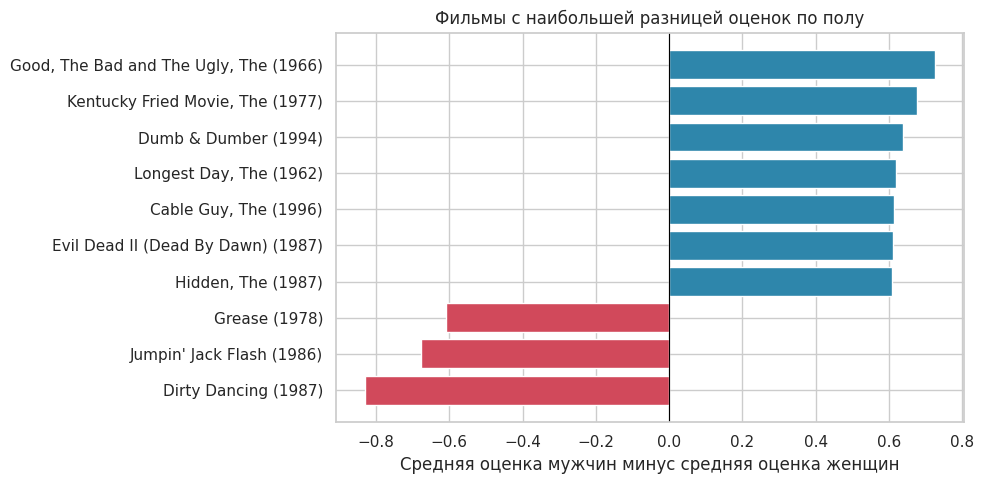

Gender,F,M
Title,,
"Good, The Bad and The Ugly, The (1966)",3.49,4.22
"Kentucky Fried Movie, The (1977)",2.88,3.56
Dumb & Dumber (1994),2.70,3.34
"Longest Day, The (1962)",3.41,4.03
"Cable Guy, The (1996)",2.25,2.86
Evil Dead II (Dead By Dawn) (1987),3.30,3.91
"Hidden, The (1987)",3.14,3.75
Grease (1978),3.98,3.37
Jumpin' Jack Flash (1986),3.25,2.58


In [16]:
delta = (mean_by_gender["M"] - mean_by_gender["F"]).dropna()
top = delta.reindex(delta.abs().nlargest(10).index).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top.index, top.values, color=["#d1495b" if v < 0 else "#2e86ab" for v in top])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Средняя оценка мужчин минус средняя оценка женщин")
ax.set_title("Фильмы с наибольшей разницей оценок по полу")
plt.tight_layout()
plt.show()

display(mean_by_gender.loc[top.index[::-1], ["F", "M"]].round(2))

## 5. Средний рейтинг жанров по возрастным группам

У фильма может быть несколько жанров (`Action|Thriller`), поэтому сначала раскладываем жанры по отдельным строкам.

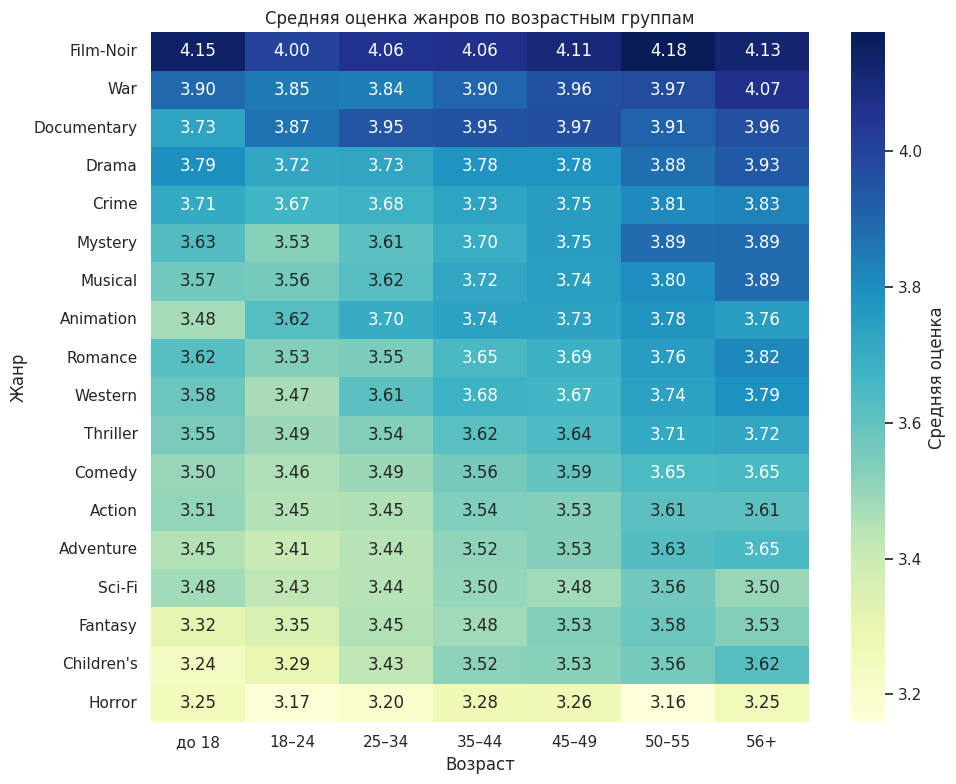

In [17]:
AGE_LABELS = {1: "до 18", 18: "18–24", 25: "25–34", 35: "35–44",
              45: "45–49", 50: "50–55", 56: "56+"}

genres = data.assign(Genres=data["Genres"].str.split("|")).explode("Genres")

by_genre_age = genres.pivot_table(
    index="Genres", columns="Age", values="Rating", aggfunc="mean"
).rename(columns=AGE_LABELS)
by_genre_age = by_genre_age.loc[by_genre_age.mean(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(10, 8))
sns.heatmap(by_genre_age, annot=True, fmt=".2f", cmap="YlGnBu",
            cbar_kws={"label": "Средняя оценка"})
plt.title("Средняя оценка жанров по возрастным группам")
plt.xlabel("Возраст")
plt.ylabel("Жанр")
plt.tight_layout()
plt.show()

### Что видно по MovieLens

- И у мужчин, и у женщин в топ-5 мультфильмы студии Aardman (серия про Уоллеса и Громита). У женщин первое место у «A Close Shave» (4.64), у мужчин у «The Wrong Trousers» (4.48).
- Сильнее всего мнения расходятся по «Dirty Dancing» (женщины 3.79, мужчины 2.96) и «The Good, the Bad and the Ugly» (мужчины 4.22, женщины 3.49).
- Во всех возрастных группах выше всего оценивается Film-Noir, ниже всего Horror. В каждом жанре группа 56+ ставит в среднем больше, чем группа 18–24.

## 6. California Housing: от чего зависит цена жилья

Набор данных составлен по переписи США 1990 года: одна строка соответствует одному кварталу. Цена `Price` задана в сотнях тысяч долларов.

In [18]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
df = housing.frame.rename(columns={"MedHouseVal": "Price"})
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


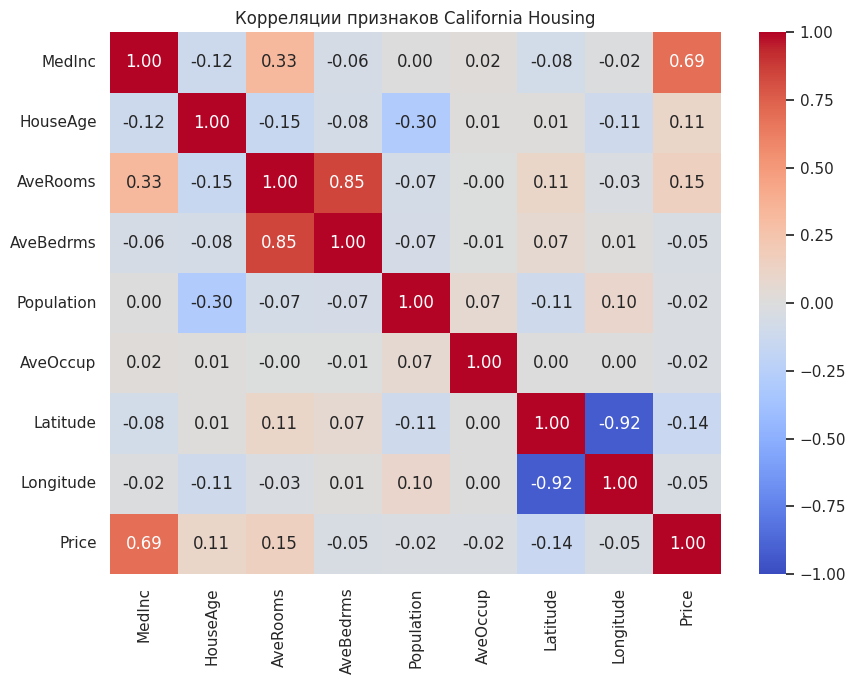

,Price
MedInc,0.69
AveRooms,0.15
HouseAge,0.11
AveOccup,-0.02
Population,-0.02
Longitude,-0.05
AveBedrms,-0.05
Latitude,-0.14


In [19]:
corr = df.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляции признаков California Housing")
plt.tight_layout()
plt.show()

display(corr["Price"].drop("Price").sort_values(ascending=False).round(2))

### Что видно по California Housing

Цена жилья сильнее всего связана с медианным доходом жителей квартала (корреляция около 0,69). С остальными признаками связь слабая: коэффициенты порядка 0,15 и меньше по модулю. Корреляция показывает связь, но не причину: например, высокий доход может быть и следствием того, что в районе дорогое жильё.

## Источники

- F. Maxwell Harper, Joseph A. Konstan. The MovieLens Datasets: History and Context. ACM TiiS 5(4), 2015.
- Pace R. K., Barry R. Sparse Spatial Autoregressions. Statistics and Probability Letters, 33 (1997), 291–297 (California Housing, через scikit-learn).